In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # تنها جای تعریف seed در نوتبوک
rng = np.random.default_rng(SEED)

from nyc311_factory.config import load_config
from nyc311_factory.pipeline import run_all
from nyc311_factory import analysis

CONFIG_PATH = os.environ.get("NYC311_CONFIG", "config/default.json")
cfg = load_config(CONFIG_PATH)
print("config:", CONFIG_PATH, "| window:", cfg.window.start, "->", cfg.window.end, "| agencies:", cfg.agencies)

config: config/default.json | window: 2023-01-01 -> 2024-07-01 | agencies: ('HPD',)


In [2]:
summary, result, manifest = run_all(cfg)
manifest = analysis.load_manifest(cfg.paths.curated)
pd.Series(manifest["records"]["quarantine_by_reason"], name="count").to_frame()

,count
CLOSED_BEFORE_CREATED,215


In [3]:
rec = manifest["records"]
print({k: rec[k] for k in ("raw", "valid", "quarantined")})
print("join:", {k: v for k, v in manifest["join"].items() if k != "note"})
print("http:", manifest["http"]["total_http_requests"], "requests; minimum possible:", manifest["http"]["minimum_possible_requests"])
print(manifest["http"]["rationale"])

{'raw': 632912, 'valid': 632697, 'quarantined': 215}
join: {'matched_population': 632603, 'population_zip_rows': 223, 'rows_after_join': 632697, 'rows_before_join': 632697, 'unmatched_population': 94}
http: 16 requests; minimum possible: 14
The server caps one response at 50000 rows, so 632912 raw records need at least ceil(632912/50000) = 13 data requests, plus 1 request for the population table. Keyset pagination needs no extra count/probe request: a short page signals the end. Anything above the minimum is retries or resumed runs.


In [4]:
quality = pd.read_csv(os.path.join(cfg.paths.curated, "data_quality_report.csv"))
quality

,column,dtype,rows,null_pct,n_unique,min,max
0,unique_key,string,632697,0.0000,>=200000,56412496,61661247
1,created_date,datetime,632697,0.0000,>=200000,2023-01-01T00:01:16,2024-06-30T23:54:19
2,closed_date,datetime,632697,0.1966,>=200000,2023-01-01T10:36:49,2026-07-08T18:11:17
3,agency,string,632697,0.0000,1,HPD,HPD
4,complaint_type,string,632697,0.0000,3,HEAT/HOT WATER,UNSANITARY CONDITION
5,descriptor,string,632697,0.0000,25,APARTMENT ONLY,Water Supply
6,status,string,632697,0.0000,4,Closed,Unspecified
7,incident_zip,string,632697,0.0128,189,10000,12345
8,borough,string,632697,0.0000,6,BRONX,UNSPECIFIED
9,zip_borough,string,632697,0.0130,5,BRONX,STATEN ISLAND


In [5]:
pd.Series(manifest["cleaning_stats"], name="count").to_frame()

,count
borough_imputed_from_zip,0
borough_unresolved,7
borough_zip_mismatch,1048
complaint_type_case_normalized,4602
descriptor_filled,0
open_cases,1244
zero_duration_cases,49
zip_missing,81
zip_not_in_population,13
zip_nullified,0


In [6]:
df = analysis.load_cases(cfg.paths.curated)
print(df.shape, "| open share: %.2f%%" % (100 * (1 - df["is_closed"].mean())))
df[["resolution_hours", "resolution_days", "population_zip", "created_hour"]].describe().round(2)

(632697, 18) | open share: 0.20%


,resolution_hours,resolution_days,population_zip,created_hour
count,631453.00,631453.00,632603.00,632697.00
mean,278.41,11.60,67246.11,12.97
std,732.53,30.52,22755.11,5.59
min,0.00,0.00,332.00,0.00
25%,27.85,1.16,50868.00,9.00
50%,55.90,2.33,70296.00,13.00
75%,173.72,7.24,82678.00,17.00
max,24143.66,1005.99,112750.00,23.00


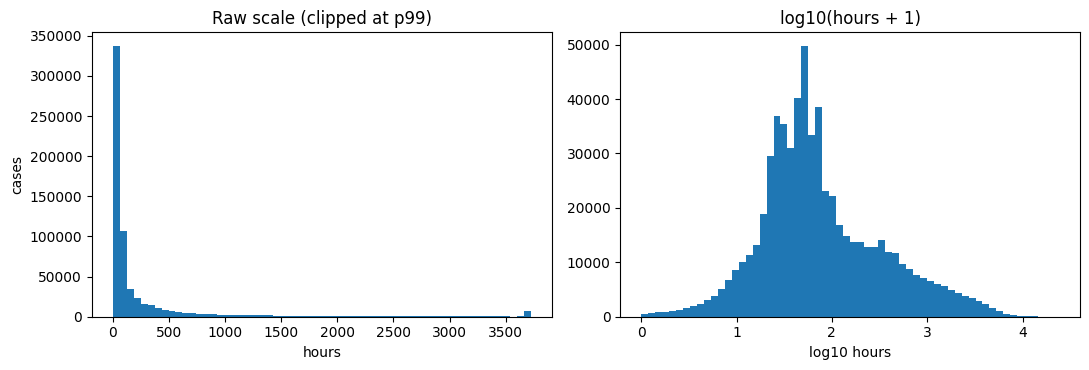

In [7]:
closed = df[df["is_closed"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(closed["resolution_hours"].clip(upper=closed["resolution_hours"].quantile(0.99)), bins=60)
axes[0].set(title="Raw scale (clipped at p99)", xlabel="hours", ylabel="cases")
axes[1].hist(np.log10(closed["resolution_hours"] + 1), bins=60)
axes[1].set(title="log10(hours + 1)", xlabel="log10 hours")
plt.tight_layout(); plt.show()

In [8]:
analysis.outlier_summary(df).round(2)

,metric,value
0,fence_low_h,0.94
1,fence_high_h,2603.08
2,n_flagged,15907.00
3,pct_flagged,2.52
4,mean_all_h,278.41
5,mean_without_outliers_h,195.86
6,median_all_h,55.90
7,median_without_outliers_h,54.75


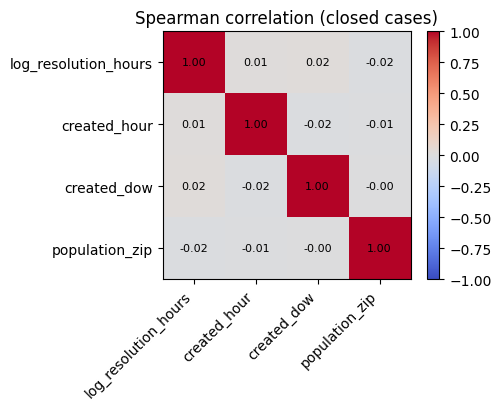

In [9]:
corr = analysis.correlation_frame(df)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Spearman correlation (closed cases)"); plt.tight_layout(); plt.show()

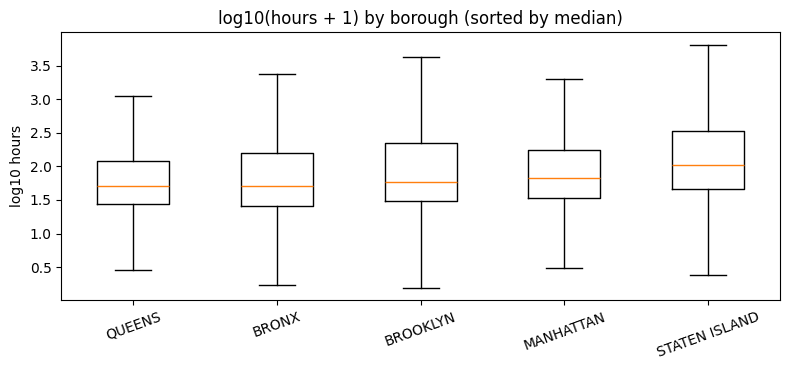

In [10]:
known = closed[closed["borough"] != "UNSPECIFIED"]
order = known.groupby("borough")["resolution_hours"].median().sort_values().index
data = [np.log10(known.loc[known["borough"] == b, "resolution_hours"] + 1) for b in order]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot(data, tick_labels=list(order), showfliers=False)
ax.set(title="log10(hours + 1) by borough (sorted by median)", ylabel="log10 hours"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

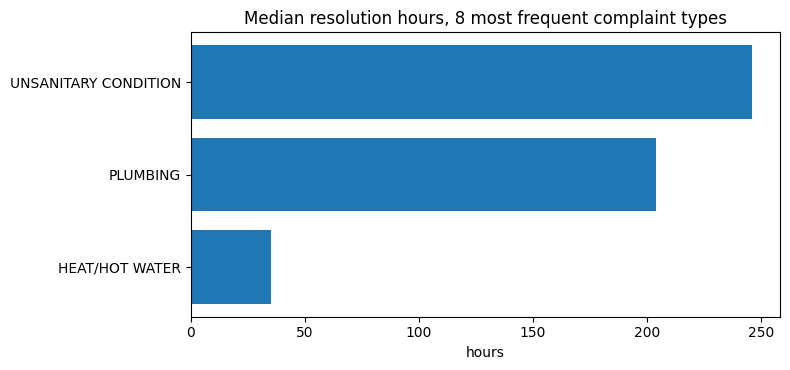

In [11]:
top = closed["complaint_type"].value_counts().head(8).index
med = closed[closed["complaint_type"].isin(top)].groupby("complaint_type")["resolution_hours"].median().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(med.index, med.values); ax.set(title="Median resolution hours, 8 most frequent complaint types", xlabel="hours")
plt.tight_layout(); plt.show()

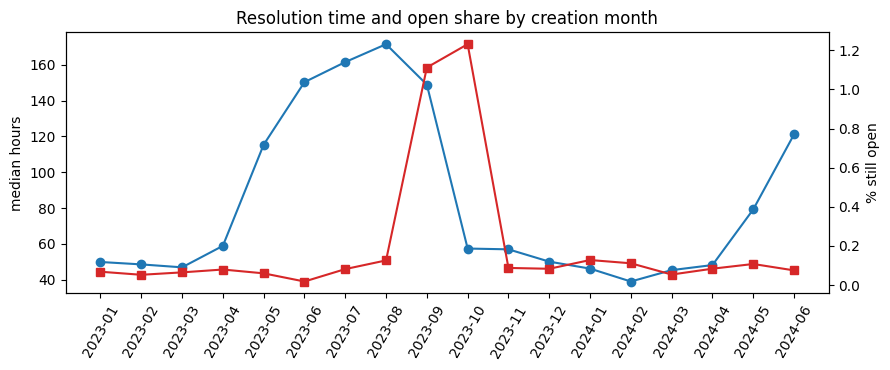

In [12]:
trend = analysis.monthly_trend(df)
fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.plot(trend.index, trend["median_hours_closed"], marker="o", label="median hours (closed cases)")
ax1.set_ylabel("median hours"); ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx(); ax2.plot(trend.index, trend["open_share_pct"], color="tab:red", marker="s", label="% still open")
ax2.set_ylabel("% still open"); ax1.set_title("Resolution time and open share by creation month")
plt.tight_layout(); plt.show()

In [13]:
for i, sentence in enumerate(analysis.findings(df), 1):
    print(f"{i}. {sentence}")

1. Borough gap: median closing time is 50.0 h in QUEENS but 102.8 h in STATEN ISLAND (2.1x).
2. Weekend effect: complaints created on weekends have median 54.4 h vs 56.5 h on weekdays.
3. Trend vs censoring: median closing time of the last 3 months is 82.9 h (higher than 48.5 h in the first 3), while 0.1% of recent cases are still open (vs 0.1%).
4. Data quality: 0.17% of cases with a usable ZIP report a borough different from the one implied by the ZIP prefix.


In [14]:
wide = analysis.load_wide(cfg.paths.curated)
print(wide.shape)
wide.iloc[:5, :8]

(17, 40)


,borough,complaint_type,borough_population,total_count,count_2023-01,count_2023-02,count_2023-03,count_2023-04
0,BRONX,HEAT/HOT WATER,1450346.0,131452,11914,12565,10162,4879
1,BRONX,PLUMBING,1450346.0,33065,1992,1787,1662,1451
2,BRONX,UNSANITARY CONDITION,1450346.0,57422,2985,2677,2845,2497
3,BROOKLYN,HEAT/HOT WATER,2679609.0,94375,7704,8597,6875,3702
4,BROOKLYN,PLUMBING,2679609.0,27946,1507,1628,1590,1332


In [15]:
print(manifest["output_hashes_sha256"])

{'case_level.csv': '558dfe96d782c725a89773078498e2eb82e8b4fc658bddc66940d987c14558d1', 'data_quality_report.csv': '8292a937876f3d8ef2815eb1a155599bd5ccaba9f6aa9914aa2c1cf3c6108e6e', 'quarantine.jsonl': '23c7cd5f234483eb815c01314aa03cde89109a8cb1fbaaf55718de90dfe97e27', 'wide_borough_type_month.csv': 'fe381fd63eb3dd9be5c187ae9d4f61279ad2bd21c004e1c8cce6502aba3a5bf3'}
